# Семинар 1. Текст как данные и предобработка

### План семинара
1. Знакомство с корпусом: что можно узнать по тексту до обучения модели
2. Токенизация: слова, пунктуация и токены готовой модели
3. Стоп-слова и пунктуация: что теряется при удалении
4. Лемматизация и стемминг
5. Регулярные выражения и нормализация

Дополнительно: поиск по леммам, стемминг английского текста и частые сочетания в отзывах.

In [ ]:
%pip install -q "pandas>=2.2,<3" "matplotlib>=3.8,<4" "nltk==3.9.2" "pymorphy3==2.0.6" "pymystem3==0.2.0" "razdel==0.5.0" "tokenizers==0.22.2"

In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

SEED = 13
LABELS = ["negative", "neutral", "positive"]
COLORS = ["#9b6b80", "#c5a46c", "#598c88"]
pd.set_option("display.max_colwidth", 180)

## 1. Знакомство с корпусом

Возьмём [RuReviews](https://github.com/sismetanin/rureviews) - русскоязычные отзывы о женской одежде и аксессуарах. В таблице 90 тысяч отзывов: по 30 тысяч положительных, нейтральных и отрицательных. Мы наследуем эту выборку от авторов корпуса.

Метки получены *автоматически* из оценок покупателей.Обратите внимания, что покупатель может хвалить вещь, но быть недовольным доставкой, или наоборот.

**Вопрос:** если в отзыве есть и похвала, и жалоба, какую метку вы бы ему поставили?

Прочитаем таблицу через `pd.read_csv`. Несмотря на расширение `.csv`, столбцы разделены табуляцией `sep="\t"`.

In [ ]:
url = "https://raw.githubusercontent.com/sismetanin/rureviews/2f6e61d30dc6c58ba47dce72e5803e1f0a3f38a7/women-clothing-accessories.3-class.balanced.csv"

В файле всего два столбца: `review` и `sentiment`. Текст переименуем в `text_raw`, а для работы с меткой добавим `label`. Заодно исправим опечатку в названии нейтрального класса: в исходнике написано `neautral` :).

Поле `id` создадим сами из номера строки. Это поможет найти запись в исходной таблице, но ничего не скажет ни об авторе, ни о товаре.

In [ ]:
raw = pd.read_csv(url, sep="\t").rename(columns={"review": "text_raw"})
raw["label"] = raw["sentiment"].replace({"neautral": "neutral"}) # ну бывает
raw.insert(0, "id", raw.index)
raw.shape

(90000, 4)

Что означают поля:

| Поле | Что в нём лежит |
|---|---|
| `id` | Номер строки в исходной таблице, начиная с 0 |
| `text_raw` | Исходный текст отзыва |
| `sentiment` | Метка из файла |
| `label` | `negative`, `neutral` или `positive` |

In [ ]:
raw

,id,text_raw,sentiment,label
0,0,качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стоит за такие деньги г.......,negative,negative
1,1,"Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.",negative,negative
2,2,"Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем как и сама кофта- мешок! На картинке кажется приталенной на с...",negative,negative
3,3,"товар не пришел, продавец продлил защиту без моего согласия. от продавца одни обещания",negative,negative
4,4,"Кофточка голая синтетика, носить не возможно.",negative,negative
...,...,...,...,...
89995,89995,сделано достаточно хорошо. на ткани сделан рисунок он почти не заметен. заказ до Москвы шёл меньше месяца,positive,positive
89996,89996,"Накидка шикарная. Спасибо большое провдо линяет немножко , но в остальном теплая, подошла по размеру ,мягкая, пришла быстро. Спасибо еще раз.",positive,positive
89997,89997,спасибо большое ) продовца рекомендую.. заказала 23.08 пришло 12.09,positive,positive
89998,89998,Очень довольна заказом! Меньше месяца в РБ. Курьер привез домой. Юбка шикарная! Очень универсальная. Спасибо большое! ! !,positive,positive


In [ ]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         90000 non-null  int64 
 1   text_raw   90000 non-null  object
 2   sentiment  90000 non-null  object
 3   label      90000 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.7+ MB


### 1.1 Пропуски, пустые строки и метки

Проверим размеры таблицы, пропуски и метки. Затем посмотрим, как устроены сами отзывы.

Пустая строка и пропуск - не одно и то же. Строка из пробелов тоже не выглядит полезным текстом, хотя `isna()` её не заметит.

In [ ]:
passport = pd.Series({
    "Записей": len(raw),
    "Пропусков в тексте": raw["text_raw"].isna().sum(),
    "Пустых текстов и строк из пробелов": raw["text_raw"].fillna("").str.strip().eq("").sum(),
    "Повторов текста сверх первого вхождения": raw["text_raw"].duplicated().sum(),
})
display(passport.to_frame("Количество"))
display(raw["sentiment"].value_counts().rename("Исходные метки"))

,Количество
Записей,90000
Пропусков в тексте,0
Пустых текстов и строк из пробелов,1
Повторов текста сверх первого вхождения,2679


,Исходные метки
sentiment,
negative,30000
neautral,30000
positive,30000


Пропусков нет, а пустой текст нашёлся. Сохраним такие строки отдельно. Для дальнейшей работы нужны непустой текст и известная метка.

In [ ]:
valid = raw["text_raw"].notna() & raw["text_raw"].str.strip().ne("") & raw["label"].isin(LABELS)
rejected = raw.loc[~valid].copy()
df = raw.loc[valid].copy()
assert df["id"].is_unique
print("Отложили строк:", len(rejected))

Отложили строк: 1


Давайте сначала прочитаем несколько отзывов. В исходном файле они идут блоками классов, поэтому возьмём по два из каждого.

**Вопросик:** всегда ли оценка покупателя понятна из текста?

In [ ]:
df.groupby("label").sample(2, random_state=SEED)[["id", "text_raw", "label"]]

,id,text_raw,label
3195,3195,"Сегодня получила свое долгожданное платье и была очень в нем разочарована( Цвет платья не как на фото,намного бледнее, заказала себе размер s и просто в нем утонула,придется уш...",negative
15960,15960,"заказ был сделан в октябре. Продержали деньги, товар так и не получила.В январе вернули деньги, без объяснения причин, сумма меньше чем я заплатила. не советую заказывать у это...",negative
35306,35306,"свитер пришел чуть больше чем через месяц, заказывала серый цвет, пришел какой то грязно белый, нитки нигде не торчат, но воротник отвратительный, нет ни резинки ни форму не де...",neutral
42480,42480,Размер не соответствует. Большие. Мех тонковат.,neutral
67050,67050,"Спасибо ! доставка быстрая отслеживается, лифчик хороший всё клеется держит",positive
69349,69349,Хорошая юбка. В талии немного великовата.,positive


### 1.2 Что можно понять по одним скобкам?

В отзывах встречаются `:)`, `:(` и улыбки из одних скобок. Можно ли по ним что-то понять об оценке покупателя? И что мы потеряем, если удалить эти знаки при очистке?

Сначала сравним, как часто разные смайлики встречаются в каждом классе. Затем прочитаем сами отзывы и проверим нашу догадку.

Ниже два простых шаблона: двоеточие, необязательный дефис и скобка; либо несколько одинаковых скобок подряд. К синтаксису регулярных выражений ещё вернёмся.

In [ ]:
smile_patterns = {
    ":) или ))": r":-?\)|\){2,}",
    ":( или ((": r":-?\(|\({2,}",
}
smile_markers = pd.DataFrame({
    name: df["text_raw"].str.contains(pattern, regex=True)
    for name, pattern in smile_patterns.items()
})
smile_counts = smile_markers.groupby(df["label"]).sum().reindex(LABELS)
smile_counts

,:) или )),:( или ((
label,,
negative,265,1333
neutral,446,1373
positive,1756,240


Посчитаем доли внутри каждого класса. Один отзыв может содержать оба вида смайликов и попасть в оба подсчёта.

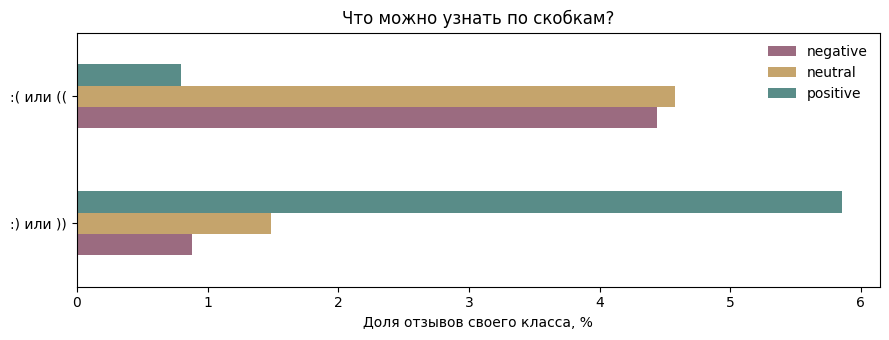

Нашли хотя бы один из шаблонов: 5302 отзывов (5.9%)


In [ ]:
smile_rates = smile_markers.groupby(df["label"]).mean().mul(100).reindex(LABELS)
ax = smile_rates.T.plot.barh(figsize=(9, 3.5), color=COLORS)
ax.set(xlabel="Доля отзывов своего класса, %", ylabel="", title="Что можно узнать по скобкам?")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

has_smile = smile_markers.any(axis=1)
print(f"Нашли хотя бы один из шаблонов: {has_smile.sum()} отзывов ({has_smile.mean():.1%})")

Связь есть. Теперь посмотрим, всегда ли она работает на отдельных примерах.

In [ ]:
df.loc[[74582, 78648, 26721, 49208, 17724], ["id", "text_raw", "label"]]

,id,text_raw,label
74582,74582,отлично:),positive
78648,78648,Спасибо)),positive
26721,26721,Не дошло(((,negative
49208,49208,Порванные колготки :),neutral
17724,17724,Лосин хватило на один день)),negative


**Вопросик:** можно ли по улыбке поставить положительную метку? Почему в двух последних отзывах она не совпала с нашей догадкой?

**Задание:** измените поиск так, чтобы он находил и одиночную `)`. Посмотрите на несколько добавившихся отзывов. Всегда ли это улыбка?

Наши исходные шаблоны нашлись только примерно в 6% отзывов. На остальных нельзя применить правило по виду найденного смайлика.

Пока оставим пунктуацию в текстах. В разделе про стоп-слова проверим, что с этими же смайликами делает удаление знаков.

In [ ]:
# ваш код

### 1.3 Длины и повторяющиеся тексты

Посмотрим, насколько длинные нам достались отзывы. Затем прочитаем самые короткие и один из самых длинных.

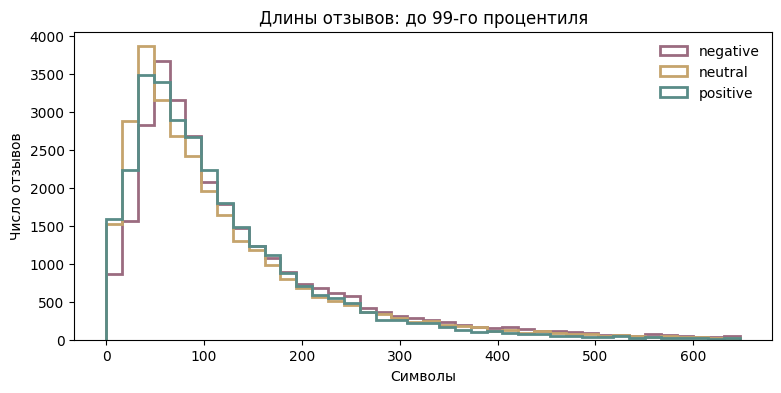

In [ ]:
df["char_count"] = df["text_raw"].str.len()
fig, ax = plt.subplots(figsize=(9, 4))
limit = df["char_count"].quantile(0.99)
for label, color in zip(LABELS, COLORS):
    lengths = df.loc[df["label"].eq(label), "char_count"]
    ax.hist(lengths, bins=40, range=(0, limit), histtype="step", linewidth=2, label=label, color=color)
ax.set(xlabel="Символы", ylabel="Число отзывов", title="Длины отзывов: до 99-го процентиля")
ax.legend(frameon=False)
plt.show()

In [ ]:
display(df.nsmallest(5, "char_count")[["id", "text_raw", "label"]])

,id,text_raw,label
1978,1978,r,negative
3959,3959,.,negative
4445,4445,.,negative
5630,5630,п,negative
5823,5823,я,negative


In [ ]:
print(df.loc[df["char_count"].idxmax(), "text_raw"])

Качество шубы просто отвратительное. Вся шуба дырявая, швы пошиты как попало, черными нитками розовая шуба! Линяет ужасно! На розовой замше красными нитками нарисовано! Замшу видно! Крючки отваливаются, и пришиты тяп ляп. (Кстати уже отдала 1800 чтобы перешить крючки!) 
Меха мало и он жидкий, линяет ппц! Сроду такого позора мехового не видела!
Продавец и размер посоветовал не верный, мне большая! Пришлось внахлест перешивать крючки!
Открыла спор, али не одобрил возврат 6000 на ремонт шубы, говорят отправьте обратно! Обратно? Серьёзно? И платить пересыл? Подала жалобу на возврат 6000, жду пересмотра спора! 
Цена шубе 8000 не больше! На один сезон шуба и то если носить раз в неделю, сыпется жутко,вся вылезет!
Продавцу написала что шуба вся бракованная, молчит! Даже не извинился! И не предложил решить вопрос!
Если али не одобрит жалобу я буду просто в шоке! Отпишусь тут по результатам. 
ШУБУ НЕ СОВЕТУЮ! НЕ ТРАТЬТЕ ДЕНЬГИ! Прийдет лысая и драная! Лучше доплатить 5000 и купить качественную!

**Вопросик:** какие из коротких текстов вы бы оставили? По одной длине это можно решить?

А теперь посмотрим на самые частые формулировки и их метки.

In [ ]:
frequent_texts = df["text_raw"].value_counts().head(5)
pd.crosstab(df["text_raw"], df["label"]).loc[frequent_texts.index, LABELS]

label,negative,neutral,positive
text_raw,,,
Товар не пришёл,45,13,0
товар не пришел,47,8,0
.,5,39,2
"товар не пришел, деньги вернули",21,21,1
супер,0,0,40


> А что делать, если один текст получил разные метки?

Такие группы в нашем корпусе есть. Давайте посмотрим на отзыв «товар не пришел, деньги вернули». Какую часть покупки здесь оценивают? По одной фразе это не очень понятно.

Можно оставить исходные отзывы, убрать повторные экземпляры или исключить формулировки с разными метками. Можно также вернуться к источнику или разметить тональность текста отдельно от покупательской оценки.

**Вопросик:** что изменится при каждом из этих решений?

### 1.4 Слово в контексте

В [NLTK Book](https://www.nltk.org/book/ch01.html#searching-text) для знакомства с текстами используют *конкорданс*: находят слово и читают его окружение.

> Конкорданс - это упорядоченный список словоформ (или слов) с указанием всех вхождений того или иного слова в заданный массив текстов;  для каждой словоформы   приведен контекст, иллюстрирующий данное  словоупотребление.

Начнём со слова «села».

In [ ]:
df.loc[[69901, 24423, 61944], ["id", "text_raw", "label"]]

,id,text_raw,label
69901,69901,Юбка села отлично. Спасибо!,positive
24423,24423,при стирке села на пару размеров,negative
61944,61944,"размеры соответствуют. после стирки не села, очень понравилась.",positive


**Задание:** найдите ещё отзывы со словом «села». Везде ли оно означает одно и то же? Какие соседние слова помогают понять смысл?

**Дополнительно:** проверьте слово «тонкая». Когда это достоинство, когда недостаток, а когда просто описание?

> Подсказка: `str.contains(r"\bсела\b", case=False)` ищет слово целиком без учёта регистра. `\b` обозначает границу слова.

In [ ]:
# ваш код

## 2. Токенизация

Токенизировать - значит, поделить текст на *токены*: слова, знаки препинания, смайлики или другие единицы. Самый наивный способ токенизировать текст - разделить на слова по пробелам с помощью `split`. Но `split` упускает очень много всего, например, не отделяет пунктуацию от слов. Кроме этого есть ещё много менее тривиальных проблем, которые мы обсудим по ходу семинара, поэтому на практике часто используют готовые токенизаторы.

In [ ]:
import nltk
from nltk.tokenize import word_tokenize

NLTK_DIR = Path("data/nltk_data")
NLTK_DIR.mkdir(parents=True, exist_ok=True)
nltk.data.path.insert(0, str(NLTK_DIR.resolve()))
nltk.download("punkt_tab", download_dir=str(NLTK_DIR), quiet=True)

True

Возьмём один отзыв и будем возвращаться к нему при обработке. Номер строки позволяет найти его в исходной таблице.

In [ ]:
example = df.loc[5698, "text_raw"]
example

'Размер не соответствует. XXL-это российский  52, а нужен был 46 :('

In [ ]:
# c помощью split()
example.split()

['Размер',
 'не',
 'соответствует.',
 'XXL-это',
 'российский',
 '52,',
 'а',
 'нужен',
 'был',
 '46',
 ':(']

In [ ]:
# c помощью токенизатора
word_tokenize(example, language="russian")

['Размер',
 'не',
 'соответствует',
 '.',
 'XXL-это',
 'российский',
 '52',
 ',',
 'а',
 'нужен',
 'был',
 '46',
 ':',
 '(']

**Вопрос:** что произошло с запятой после `52` и со смайликом `:(`?

`language="russian"` выбирает модель разбиения на предложения. Сами слова делит `NLTKWordTokenizer` с правилами на основе английского Treebank. То есть этот параметр не превращает `word_tokenize` в специальный токенизатор русского языка.

<details>
<summary>Ещё несколько инструментов nltk.tokenize</summary>

У NLTK есть разные токенизаторы. Посмотреть их можно через `dir(nltk.tokenize)`.

`nltk.tokenize.WhitespaceTokenizer().span_tokenize(example)` возвращает позиции частей, разделённых пробелами.

`nltk.tokenize.TreebankWordTokenizer().tokenize("don't stop me")` разделит `don't` на `do` и `n't`.

`nltk.tokenize.SExprTokenizer().tokenize("(a (b c)) d e (f)")` работает с S-выражениями, а не с обычными предложениями.

</details>

Есть токенизатор, который может быть полезен для работы с твитами или сообщениями из соц. сетей. Он сохранит смайлики, хештеги и т.п.

In [ ]:
from nltk.tokenize import TweetTokenizer

tw = TweetTokenizer()
tw.tokenize(example)

['Размер',
 'не',
 'соответствует',
 '.',
 'XXL-это',
 'российский',
 '52',
 ',',
 'а',
 'нужен',
 'был',
 '46',
 ':(']

Для русского языка есть [razdel](https://github.com/natasha/razdel). Он выделяет слова и предложения по правилам - без использования отдельной модели.

In [ ]:
from razdel import tokenize as razdel_tokenize

razdel_tokens = list(razdel_tokenize(example))
pd.DataFrame({
    "токен": [token.text for token in razdel_tokens],
    "начало": [token.start for token in razdel_tokens],
    "конец": [token.stop for token in razdel_tokens],
})

,токен,начало,конец
0,Размер,0,6
1,не,7,9
2,соответствует,10,23
3,.,23,24
4,XXL-это,25,32
5,российский,33,43
6,52,45,47
7,",",47,48
8,а,49,50
9,нужен,51,56


На нашем первом отзыве razdel и TweetTokenizer дали одинаковые токены. Но так бывает не всегда. Посмотрим ещё два настоящих отзыва.

Позиции токенов - индексы символов исходной строки: `example[start:stop]`. Они пригодятся, если нужно подсветить найденное слово в тексте.

In [ ]:
tokenizer_examples = df.loc[[27, 335], ["text_raw"]].copy()
tokenizer_examples["TweetTokenizer"] = tokenizer_examples["text_raw"].map(tw.tokenize)
tokenizer_examples["razdel"] = tokenizer_examples["text_raw"].map(
    lambda text: [token.text for token in razdel_tokenize(text)]
)
tokenizer_examples

,text_raw,TweetTokenizer,razdel
27,"ставлю 1звезду, т.к товар не пришел. ждала с мая по сентябрь. деньги вернули.","[ставлю, 1звезду, ,, т, ., к, товар, не, пришел, ., ждала, с, мая, по, сентябрь, ., деньги, вернули, .]","[ставлю, 1, звезду, ,, т, ., к, товар, не, пришел, ., ждала, с, мая, по, сентябрь, ., деньги, вернули, .]"
335,пишут что теплые а на деле ооооочень тонкие,"[пишут, что, теплые, а, на, деле, ооочень, тонкие]","[пишут, что, теплые, а, на, деле, ооооочень, тонкие]"


**Вопросик:** что случилось с `1звезду` и `ооооочень`? Если мы хотим посчитать, насколько покупатели растягивают слова, какой столбец нужно использовать?

У TweetTokenizer есть и встроенная обработка повторов. Поэтому для статистик исходного написания берём `text_raw`. [Правила TweetTokenizer](https://www.nltk.org/_modules/nltk/tokenize/casual.html).

**Задание:** сравните `split()`, `word_tokenize`, `TweetTokenizer` и `razdel` на отзыве ниже. Проверьте смайлик, числа и знаки, прилепленные к словам. Какой результат вам удобнее для подсчёта слов? А для поиска смайликов?

In [ ]:
another_example = df.loc[36207, "text_raw"]
print(another_example)

# ваш код

Нормальная футболка,цвет как и представлено,но одно но нитки торчат повсюду:(запаха нет,размер на 42 рус заказала М не ошиблась 


<details>
<summary>Другие инструменты nltk.tokenize: справочная таблица</summary>

| **Токенайзер**               | **Описание**                                                                                                                                                         | **Особенности / Примечания**                                                                 |
|------------------------------|----------------------------------------------------------------------------------------------------------------------------------------------------------------------|----------------------------------------------------------------------------------------------|
| `word_tokenize`              | `NLTKWordTokenizer` после разбиения на предложения через Punkt; правила слов основаны на английском Treebank.                                                           | Хорош для общего использования, обрабатывает сокращения и пунктуацию.                      |
| `sent_tokenize`              | Делит текст на предложения. Использует обученную модель `Punkt`.                                                                                                    | Поддержка разных языков (можно загрузить соответствующую модель через `nltk.download`).    |
| `WordPunctTokenizer`         | Разбивает слова и пунктуацию с помощью регулярных выражений.                                                                                                       | Прост и быстр, но не обрабатывает сокращения.                                               |
| `TreebankWordTokenizer`      | Токенизирует по правилам Penn Treebank.                                                                                                                             | Хорошо работает с английским, разбивает «don't» на `do` и `n't`.                           |
| `PunktSentenceTokenizer`     | Обучаемый токенайзер предложений.                                                                                                                                    | Учитывает аббревиатуры, имена, сокращения. Используется внутри `sent_tokenize`.            |
| `TweetTokenizer`             | Адаптирован для текстов из соцсетей (Twitter).                                                                                                                     | Учитывает эмодзи, хэштеги, повторения символов и т. п.                                      |
| `RegexpTokenizer`            | Пользователь может задать регулярное выражение для извлечения токенов.                                                                                             | Гибкость при нестандартной структуре текста.                                                |
| `MWETokenizer`               | Многословные выражения (Multi-Word Expressions), задаются вручную (например, `('New', 'York')`).                                                                   | Полезен для задач NER, где нужно сохранить устойчивые фразы как единый токен.              |
| `TextTilingTokenizer`        | Делит текст на тематически однородные сегменты.                                                                                                                    | Используется для анализа структуры больших текстов, например, статей.                      |
| `WhitespaceTokenizer`        | Разбивает текст по пробельным символам, включая табуляции и переносы строк.                                                                                                                                 | Очень простой, не обрабатывает пунктуацию.                                                  |
| `BlanklineTokenizer`         | Делит текст на параграфы по пустым строкам.                                                                                                                        | Полезен для предварительной обработки при работе с документами.                            |
| `LineTokenizer`              | Делит текст по строкам (по символу перевода строки).                                                                                                               | Полезен при работе с логами, списками.                                                      |
| `SpaceTokenizer`             | Разделение только по пробелу `' '`.                                                                                                                                 | Отличается от `WhitespaceTokenizer`, так как не учитывает табуляции.                       |
| `TabTokenizer`               | Разделение по табуляции.                                                                                                                                           | Узкоспециализированный.                                                                    |
| `SyllableTokenizer`          | Токенизация по слогам, основанная на сонорности.                                                                                                                   | Используется в лингвистических исследованиях.                                               |
| `LegalitySyllableTokenizer`  | Также для слогов, но основан на принципе легальности и максимизации онсета (начального созвучия).                                                                 | Теоретически обоснованная модель слоговой структуры.                                        |
| `StanfordSegmenter`          | Интерфейс к внешнему инструменту - Stanford NLP Segmenter (Java). Поддерживает китайский, арабский и другие языки.                                                | Требует установки Stanford NLP и Java.                                                      |
| `ToktokTokenizer`            | Порт популярного токенизатора с Perl (`tok-tok.pl`).                                                                                                               | Универсальный токенайзер, подходит для многих языков.                                       |
| `ReppTokenizer`              | Обёртка над REPP (Rule-based English Preprocessing Pipeline) - токенайзером на основе правил для английского.                                                    | Требует установки REPP (написан на C++), может использоваться для точной разметки корпуса. |
| `SExprTokenizer`             | Разделяет текст по s-выражениям (для лиспоподобных структур).                                                                                                      | Полезен при обработке парсеров и синтаксических деревьев.                                  |
| `TreebankWordDetokenizer`    | Объединяет токены обратно в строку по правилам Treebank.                                                                                                           | Противоположен `TreebankWordTokenizer`.                                                     |                                                                                                                        

</details>

### А какие токены получает нейросетевая модель?

У готовой модели есть свой токенизатор и словарь. В нём токеном может быть целое слово или его часть. Подробно алгоритмы subword-токенизации разберём позже, а сейчас посмотрим результат на нашем отзыве.

Возьмём токенизатор [rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2) через библиотеку [Hugging Face Tokenizers](https://huggingface.co/docs/tokenizers/en/quicktour#using-a-pretrained-tokenizer). Скачается только файл токенизатора, веса модели нам не нужны. Разбираем исходный отзыв без удаления слов и лемматизации.

In [ ]:
from tokenizers import Tokenizer

model_tokenizer = Tokenizer.from_pretrained("cointegrated/rubert-tiny2")
subword_example = df.loc[36207, "text_raw"]
print(subword_example)
encoded = model_tokenizer.encode(subword_example, add_special_tokens=False)
pd.DataFrame({"токен": encoded.tokens, "id в словаре": encoded.ids})

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

Нормальная футболка,цвет как и представлено,но одно но нитки торчат повсюду:(запаха нет,размер на 42 рус заказала М не ошиблась 


,токен,id в словаре
0,Норма,45810
1,##льная,7269
2,футбол,16620
3,##ка,872
4,",",16
5,цвет,19403
6,как,1150
7,и,320
8,представлено,40511
9,",",16


**Вопрос:** найдите, на какие части разбились «футболка», «нитки» и «торчат». Значок `##` в WordPiece отмечает продолжение слова. Эти части определяются словарём токенизатора и не обязаны совпадать с корнем и окончанием.

Сейчас считаем только токены текста, поэтому отключили служебные токены через `add_special_tokens=False`. При обычной подготовке входа модели они тоже могут занимать место.

In [ ]:
pd.Series({
    "Частей после split()": len(subword_example.split()),
    "Токенов razdel": len(list(razdel_tokenize(subword_example))),
    "Токенов rubert-tiny2 без служебных": len(encoded.ids),
})

,0
Частей после split(),18
Токенов razdel,26
Токенов rubert-tiny2 без служебных,33


**Задание:** повторите сравнение для первого отзыва `example`. Если ограничение задано в токенах модели, можно ли проверять длину через `len(text.split())`?

Токенизатор выбирают вместе с моделью: её словарь задаёт соответствие токенов и числовых id. То есть Razdel и TweetTokenizer пригодятся нам для анализа слов, а вход готовой модели нужно собирать её собственным токенизатором.

In [ ]:
# ваш код

## 3. Стоп-слова и пунктуация

*Стоп-слова* - это частые слова, которые иногда исключают при работе с текстами. В готовый список могут входить предлоги, союзы, местоимения и отрицания. Давайте посмотрим на список и проверим, что произойдёт с нашими отзывами.

In [ ]:
nltk.download("stopwords", download_dir=str(NLTK_DIR), quiet=True)

True

In [ ]:
from nltk.corpus import stopwords

print(stopwords.words("russian"))

['и', 'в', 'во', 'не', 'что', 'он', 'на', 'я', 'с', 'со', 'как', 'а', 'то', 'все', 'она', 'так', 'его', 'но', 'да', 'ты', 'к', 'у', 'же', 'вы', 'за', 'бы', 'по', 'только', 'ее', 'мне', 'было', 'вот', 'от', 'меня', 'еще', 'нет', 'о', 'из', 'ему', 'теперь', 'когда', 'даже', 'ну', 'вдруг', 'ли', 'если', 'уже', 'или', 'ни', 'быть', 'был', 'него', 'до', 'вас', 'нибудь', 'опять', 'уж', 'вам', 'ведь', 'там', 'потом', 'себя', 'ничего', 'ей', 'может', 'они', 'тут', 'где', 'есть', 'надо', 'ней', 'для', 'мы', 'тебя', 'их', 'чем', 'была', 'сам', 'чтоб', 'без', 'будто', 'чего', 'раз', 'тоже', 'себе', 'под', 'будет', 'ж', 'тогда', 'кто', 'этот', 'того', 'потому', 'этого', 'какой', 'совсем', 'ним', 'здесь', 'этом', 'один', 'почти', 'мой', 'тем', 'чтобы', 'нее', 'сейчас', 'были', 'куда', 'зачем', 'всех', 'никогда', 'можно', 'при', 'наконец', 'два', 'об', 'другой', 'хоть', 'после', 'над', 'больше', 'тот', 'через', 'эти', 'нас', 'про', 'всего', 'них', 'какая', 'много', 'разве', 'три', 'эту', 'моя', 'впр

In [ ]:
print(stopwords.words("english"))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [ ]:
from string import punctuation

punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

<details>
<summary>Другие константы модуля string</summary>


| Константа               | Описание                                           |
|--------------------------|----------------------------------------------------|
| `ascii_letters`          | `'abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ'` |
| `ascii_lowercase`        | `'abcdefghijklmnopqrstuvwxyz'`                      |
| `ascii_uppercase`        | `'ABCDEFGHIJKLMNOPQRSTUVWXYZ'`                      |
| `digits`                 | `'0123456789'`                                     |
| `hexdigits`              | `'0123456789abcdefABCDEF'`                         |
| `octdigits`              | `'01234567'`                                       |
| `punctuation`            | `'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'`              |
| `printable`              | Все печатные символы (включая пробел и пунктуацию) |
| `whitespace`             | `' \t\n\r\x0b\x0c'` (все пробельные символы)        |

</details>

In [ ]:
noise = stopwords.words("russian") + list(punctuation)

In [ ]:
noise

['и',
 'в',
 'во',
 'не',
 'что',
 'он',
 'на',
 'я',
 'с',
 'со',
 'как',
 'а',
 'то',
 'все',
 'она',
 'так',
 'его',
 'но',
 'да',
 'ты',
 'к',
 'у',
 'же',
 'вы',
 'за',
 'бы',
 'по',
 'только',
 'ее',
 'мне',
 'было',
 'вот',
 'от',
 'меня',
 'еще',
 'нет',
 'о',
 'из',
 'ему',
 'теперь',
 'когда',
 'даже',
 'ну',
 'вдруг',
 'ли',
 'если',
 'уже',
 'или',
 'ни',
 'быть',
 'был',
 'него',
 'до',
 'вас',
 'нибудь',
 'опять',
 'уж',
 'вам',
 'ведь',
 'там',
 'потом',
 'себя',
 'ничего',
 'ей',
 'может',
 'они',
 'тут',
 'где',
 'есть',
 'надо',
 'ней',
 'для',
 'мы',
 'тебя',
 'их',
 'чем',
 'была',
 'сам',
 'чтоб',
 'без',
 'будто',
 'чего',
 'раз',
 'тоже',
 'себе',
 'под',
 'будет',
 'ж',
 'тогда',
 'кто',
 'этот',
 'того',
 'потому',
 'этого',
 'какой',
 'совсем',
 'ним',
 'здесь',
 'этом',
 'один',
 'почти',
 'мой',
 'тем',
 'чтобы',
 'нее',
 'сейчас',
 'были',
 'куда',
 'зачем',
 'всех',
 'никогда',
 'можно',
 'при',
 'наконец',
 'два',
 'об',
 'другой',
 'хоть',
 'после',
 'на

In [ ]:
tokenized_example = tw.tokenize(example.lower())
[token for token in tokenized_example if token not in noise]

['размер', 'соответствует', 'xxl-это', 'российский', '52', 'нужен', '46', ':(']

**Вопросик:** почему `:(` не попал в `noise`, хотя состоит из знаков препинания?

Вернёмся к улыбкам из EDA. Уберём токены, которые входят в `string.punctuation`, и сравним три коротких отзыва.

In [ ]:
smile_examples = df.loc[[74582, 78648, 72728], ["text_raw"]].copy()
smile_examples["токены"] = smile_examples["text_raw"].map(tw.tokenize)
punctuation_tokens = set(punctuation)
smile_examples["после фильтра"] = smile_examples["токены"].map(
    lambda tokens: [token for token in tokens if token not in punctuation_tokens]
)
smile_examples

,text_raw,токены,после фильтра
74582,отлично:),"[отлично, :)]","[отлично, :)]"
78648,Спасибо)),"[Спасибо, ), )]",[Спасибо]
72728,))),"[), ), )]",[]


**Задание:** объясните, почему `:)` сохранился, а `))` исчезли. Что осталось от третьего отзыва? Затем замените условие на `token.isalpha()` и сравните результат.

Удаление пунктуации зависит и от того, как текст был разбит на токены. Для анализа улыбок сохраним их признаки из исходных строк.

In [ ]:
# ваш код

А теперь на совсем коротком отзыве. Сравните исходную фразу и результат.

In [ ]:
short_review = df.loc[2298, "text_raw"]
print(short_review)
print(" ".join(token for token in tw.tokenize(short_review) if token not in noise))

не подошел размер
подошел размер


**Вопрос:** какую мысль выражает получившийся текст?

Попробуем сохранить отрицания, исключив их из списка стоп-слов.

In [ ]:
stop_words = set(stopwords.words("russian")) - {"не", "нет", "ни"}
noise = stop_words | set(punctuation)
print(" ".join(token for token in tw.tokenize(short_review) if token not in noise))

не подошел размер


**Задание:** найдите в корпусе положительные отзывы со словом `не`. Прочитайте несколько примеров. Что в них отрицается?

In [ ]:
# ваш код

## 4. Лемматизация и стемминг
### 4.1 Лемматизация

[**Лемматизация**](https://en.wikipedia.org/wiki/Lemmatisation) - процесс приведения слова к его нормальной форме (**лемме**):
- для существительных - именительный падеж, единственное число;
- для прилагательных - именительный падеж, единственное число, мужской род;
- для глаголов, причастий, деепричастий - глагол в инфинитиве.

Например, токены «пью», «пил», «пьет» перейдут в «пить». Когда это полезно?
* Во-первых, мы можем захотеть объединить разные формы одного слова в один признак.
* Во-вторых, некоторые стоп-слова стоят только в начальной форме, и без лемматизации выкидываем мы только её.

Для русского есть два хороших лемматизатора: `mystem` и `pymorphy`.

#### [Mystem](https://github.com/nlpub/pymystem3)

Mystem - морфологический анализатор, который можно запускать из терминала или через Python-обёртку `pymystem3`. [Справочник методов обертки](https://pythonhosted.org/pymystem3/pymystem3.html).

При первом запуске `Mystem()` обёртка скачает отдельный исполняемый файл анализатора. Для этого нужен доступ к интернету.

In [ ]:
from pymystem3 import Mystem

mystem_analyzer = Mystem()

Installing mystem to /root/.local/bin/mystem from http://download.cdn.yandex.net/mystem/mystem-3.1-linux-64bit.tar.gz


Мы инициализировали Mystem c дефолтными параметрами. А вообще параметры есть такие:
* mystem_bin - путь к `mystem`, если их несколько
* grammar_info - нужна ли грамматическая информация или только леммы (по умолчанию нужна)
* disambiguation - нужно ли снятие [омонимии](https://ru.wikipedia.org/wiki/%D0%9E%D0%BC%D0%BE%D0%BD%D0%B8%D0%BC%D1%8B) - дизамбигуация (по умолчанию нужна)

> *Здесь дизамбигуация - выбор морфологического разбора с учётом окружающего текста. Например, «сорока» может быть формой числительного или названием птицы.*

* entire_input - нужно ли сохранять в выводе все (пробелы, например), или можно выкинуть (по умолчанию оставляется все)

Методы Mystem принимают строку, токенизатор вшит внутри. Можно, конечно, и пословно анализировать, но тогда он не сможет учитывать контекст.

Можно просто лемматизировать текст:

In [ ]:
print(mystem_analyzer.lemmatize(example))

['размер', ' ', 'не', ' ', 'соответствовать', '. ', 'XXL', '-', 'это', ' ', 'российский', '  ', '52', ', ', 'а', ' ', 'нужный', ' ', 'быть', ' ', '46', ' :(\n']


### [Pymorphy3](https://github.com/no-plagiarism/pymorphy3)
Это модуль на питоне, довольно быстрый и с кучей функций.

In [ ]:
from pymorphy3 import MorphAnalyzer

In [ ]:
pymorphy3_analyzer = MorphAnalyzer()

pymorphy3 работает с отдельными словами. Если дать ему на вход предложение, то он его просто не лемматизирует, т.к. не понимает.

Метод MorphAnalyzer.parse() принимает слово и возвращает все возможные его разборы.

У каждого разбора есть тег. Тег - это набор граммем, характеризующих данное слово.

> Например, тег '*VERB,perf,intr plur,past,indc*' означает, что слово - глагол (VERB) совершенного вида (perf), непереходный (intr), множественного числа (plur), прошедшего времени (past), изъявительного наклонения (indc).

In [ ]:
ana = pymorphy3_analyzer.parse(tokenized_example[2])
ana

[Parse(word='соответствует', tag=OpencorporaTag('VERB,impf,intr sing,3per,pres,indc'), normal_form='соответствовать', score=1.0, methods_stack=((DictionaryAnalyzer(), 'соответствует', 177, 5),))]

In [ ]:
ana[0].normal_form

'соответствовать'

### Теги MorphAnalyzer

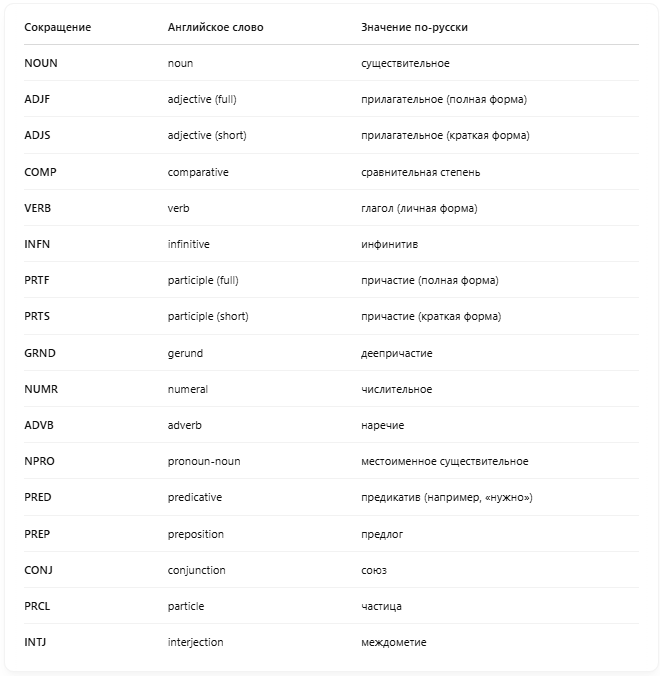

<details>
<summary>Граммемы: справочная таблица</summary>

Граммемы (морфологические признаки):

| Сокр.     | Английское слово      | Значение по-русски                     |
|-----------|------------------------|----------------------------------------|
| **masc**  | masculine              | мужской род                            |
| **femn**  | feminine               | женский род                            |
| **neut**  | neuter                 | средний род                            |
| **sing**  | singular               | единственное число                     |
| **plur**  | plural                 | множественное число                    |
| **nomn**  | nominative             | именительный падеж                     |
| **gent**  | genitive               | родительный падеж                      |
| **datv**  | dative                 | дательный падеж                        |
| **accs**  | accusative             | винительный падеж                      |
| **ablt**  | instrumental           | творительный падеж                     |
| **loct**  | locative               | предложный падеж                       |
| **voct**  | vocative               | звательный падеж (устаревшее)         |
| **gen2**  | second genitive        | второй родительный                     |
| **acc2**  | second accusative      | второй винительный                     |
| **loc2**  | second locative        | второй предложный                      |
| **perf**  | perfective             | совершенный вид                        |
| **impf**  | imperfective           | несовершенный вид                      |
| **tran**  | transitive             | переходный                             |
| **intr**  | intransitive           | непереходный                           |
| **pres**  | present                | настоящее время                        |
| **past**  | past                   | прошедшее время                        |
| **futr**  | future                 | будущее время                          |
| **1per**  | first person           | первое лицо                            |
| **2per**  | second person          | второе лицо                            |
| **3per**  | third person           | третье лицо                            |
| **indc**  | indicative             | изъявительное наклонение               |
| **impr**  | imperative             | повелительное наклонение               |
| **actv**  | active                 | действительный залог                   |
| **pssv**  | passive                | страдательный залог                    |
| **incl**  | inclusive              | включающее (мы = я + ты) (редко)       |
| **excl**  | exclusive              | исключающее (мы ≠ ты) (редко)          |
| **anim**  | animate                | одушевлённое                           |
| **inan**  | inanimate              | неодушевлённое                         |


</details>

### mystem vs. pymorphy

*Снятие омонимии*. Mystem умеет снимать омонимию по контексту (хотя не всегда преуспевает), pymorphy3 берет на вход одно слово и соответственно вообще не умеет дизамбигуировать по контексту.

In [ ]:
homonym1 = "За время обучения я прослушал больше сорока курсов."
homonym2 = "Сорока своровала блестящее украшение со стола."

# корректно определил части речи
# NUM - числительное
# S - существительное

print(mystem_analyzer.analyze(homonym1)[-5])
print(mystem_analyzer.analyze(homonym2)[0])

{'analysis': [{'lex': 'сорок', 'wt': 0.8710292664, 'gr': 'NUM=(пр|дат|род|твор)'}], 'text': 'сорока'}
{'analysis': [{'lex': 'сорока', 'wt': 0.1210970041, 'gr': 'S,жен,од=им,ед'}], 'text': 'Сорока'}


**Дополнительный пример:** посмотрим на неоднозначность в настоящем отзыве. Какой разбор слова `пришли` подходит здесь?

In [ ]:
print(df.loc[60481, "text_raw"])
pymorphy3_analyzer.parse("пришли")

Штаны отличные, пришли быстро, на 50 размер подходит 31. Продавца рекомендую!


[Parse(word='пришли', tag=OpencorporaTag('VERB,perf,tran sing,impr,excl'), normal_form='прислать', score=0.5, methods_stack=((DictionaryAnalyzer(), 'пришли', 1392, 13),)),
 Parse(word='пришли', tag=OpencorporaTag('VERB,perf,intr plur,past,indc'), normal_form='прийти', score=0.5, methods_stack=((DictionaryAnalyzer(), 'пришли', 2662, 5),))]

У слова есть разборы от «прийти» и от «прислать». Анализатор получает одно слово, поэтому первый вариант не обязательно подходит к предложению.

### **Дополнительно.** Зачем лемматизация поиску?

Допустим, мы ищем упоминания слова «размер». Точный поиск этого токена пропустит «размером», «размеру» и другие формы. В [NLTK Book](https://www.nltk.org/book/ch03.html#normalizing-text) нормализацию используют именно для расширения поиска. Попробуем тогда это на наших отзывах.

Возьмём 500 случайных отзывов.

In [ ]:
search_reviews = df.sample(500, random_state=SEED).copy()
search_reviews["tokens"] = search_reviews["text_raw"].map(
    lambda text: [token.text.lower() for token in razdel_tokenize(text)]
)
search_reviews["lemmas"] = search_reviews["tokens"].map(
    lambda tokens: [pymorphy3_analyzer.parse(token)[0].normal_form for token in tokens]
)
exact_match = search_reviews["tokens"].map(lambda tokens: "размер" in tokens)
lemma_match = search_reviews["lemmas"].map(lambda lemmas: "размер" in lemmas)
pd.Series({"По точному токену": exact_match.sum(), "По лемме": lemma_match.sum()})

,0
По точному токену,72
По лемме,104


**Задание:** покажите три отзыва, которые нашлись только во втором случае. Выпишите формы слова, которые помогли их найти.

А найдёт ли такой поиск все отзывы о проблемах с размером? Для проверки прочитайте отзыв 2494. Объясните, что ещё может пропустить поиск по одной лемме.

Здесь мы используем первый разбор pymorphy3. Как мы уже видели выше, его нужно проверять по контексту.

In [ ]:
# ваш код

### 4.2 Стемминг

В отличие от лемматизации, при применении стемминга слова сокращаются по языковым правилам, что необязательно приводит слова к формам, существующим в рассматриваемом языке. [**Snowball**](https://snowballstem.org/) - фрэймворк для написания алгоритмов стемминга. Алгоритмы стемминга отличаются для разных языков и используют знания о конкретном языке: списки окончаний для разных частей речи, разных склонений и т.д.

In [ ]:
from nltk.stem.snowball import SnowballStemmer

In [ ]:
tokenized_example = tw.tokenize(example.lower())

In [ ]:
stemmer = SnowballStemmer("russian")
stemmed_example = [stemmer.stem(w) for w in tokenized_example]
print(" ".join(stemmed_example))

размер не соответств . xxл-эт российск 52 , а нуж был 46 :(


Сравним результат со словарными формами тех же токенов.

In [ ]:
pd.DataFrame({
    "токен": tokenized_example,
    "стем": stemmed_example,
    "лемма pymorphy3": [pymorphy3_analyzer.parse(token)[0].normal_form for token in tokenized_example],
})

,токен,стем,лемма pymorphy3
0,размер,размер,размер
1,не,не,не
2,соответствует,соответств,соответствовать
3,.,.,.
4,xxl-это,xxл-эт,xxl-это
5,российский,российск,российский
6,52,52,52
7,",",",",","
8,а,а,а
9,нужен,нуж,нужный


## 5. Регулярные выражения и нормализация

Вообще, часто бывает так, что для конкретного случая нужен особый способ токенизации, и надо самостоятельно написать правило шаблонного типа для определения того, что такое токен. Или, например, перед работой с текстом, надо почистить его от своеобразного мусора: упоминаний пользователей, url и так далее. В таких задачах могут помочь регулярные выражения. Навык полезный, давайте в нём тоже потренируемся.

In [ ]:
import re

Сначала разберём синтаксис на коротких строках, затем применим те же операции к отзывам.

### findall
возвращает список всех найденных совпадений

- ? : ноль или одно повторение
- \* : ноль или более повторений
- \+ : одно или более повторений
- . : любой символ

In [ ]:
result = re.findall("ab+c.", "abcdefghijkabcabcxabc")
print(result)

['abcd', 'abca']


In [ ]:
# a - сначала ищем букву a
# b+ - затем одну или более букв b
# c - потом c
# . - и один любой символ после этого

Вопрос на внимательность: почему нет abcx?

In [ ]:
re.findall("ab+c.", "abbbca")

['abbbca']

### split
разделяет строку по заданному шаблону

In [ ]:
result = re.split(",", "itsy, bitsy, teenie, weenie")
print(result)

['itsy', ' bitsy', ' teenie', ' weenie']


можно указать максимальное количество разбиений

In [ ]:
result = re.split(",", "itsy, bitsy, teenie, weenie", maxsplit=2)
print(result)

['itsy', ' bitsy', ' teenie, weenie']


### sub
ищет шаблон в строке и заменяет все совпадения на указанную подстроку

параметры: (pattern, repl, string)

In [ ]:
result = re.sub("a", "b", "abcabc")
print(result)

bbcbbc


При этом в качестве repl, можно передавать не только строку, но и функцию, которая принимает на вход [Match](https://docs.python.org/3/library/re.html#match-objects) объект. Можно делать что-то типо этого:

In [ ]:
counter = 0


def count(match):
    global counter
    counter += 1
    return f"(a#{counter})"


re.sub("a", count, "abcabc")

'(a#1)bc(a#2)bc'

Кстати, c объектами типа re.Match работают и многие другие методы re. Например, метод re.finditer в отличии от re.findall будет возвращать те самые re.Match.

In [ ]:
for match in re.finditer("ab+c.", "abcdefghijkabcabcxabc"):
    print(match)

<re.Match object; span=(0, 4), match='abcd'>
<re.Match object; span=(11, 15), match='abca'>


Помимо найденных строчек объекты Match также, например, содержат информацию о позиции найденного "совпадения" в строке (span)

In [ ]:
match.group()   # само совпадение, напр. 'abcd'
match.start()   # индекс начала совпадения
match.end()     # индекс конца совпадения
match.span()    # кортеж (start, end)

(11, 15)

### compile
компилирует регулярное выражение в отдельный объект

In [ ]:
# Пример: построение списка всех слов строки:

prog = re.compile(r"[А-Яа-яЁё]+(?:-[А-Яа-яЁё]+)*")
prog.findall(example)

['Размер', 'не', 'соответствует', 'это', 'российский', 'а', 'нужен', 'был']

В шаблоне `[А-Яа-яЁё]+` означает одну или несколько русских букв. Часть `(?:-[А-Яа-яЁё]+)*` разрешает продолжение через дефис, но не отдельную цепочку дефисов.

### 5.1 Числа и размеры в отзывах

Вернёмся к нашему отзыву. Сначала найдём числа, затем посмотрим на результат их удаления.

In [ ]:
print(example)
re.findall(r"\d+", example)

Размер не соответствует. XXL-это российский  52, а нужен был 46 :(


['52', '46']

In [ ]:
re.sub(r"\d+", "", example)

'Размер не соответствует. XXL-это российский  , а нужен был  :('

**Вопрос:** какая информация исчезла? Нужна ли она, чтобы понять претензию покупателя?

В другом отзыве указан диапазон размеров.

In [ ]:
size_example = df.loc[79378, "text_raw"]
print(size_example)
re.findall(r"\d+-\d+", size_example)

Отличная блузка. На наш размер 46-48 взяла  XL. Вполне можно было брать L.


['46-48']

**Задание:** найдите отзывы с диапазоном размеров, например из двух чисел через дефис. Посмотрите на несколько результатов: всегда ли нашлось именно обозначение размера?

In [ ]:
# ваш код

### 5.2 Лишние пробелы и переносы

Посмотрим на три настоящих отзыва. `repr` поможет увидеть пробелы и переносы, которые обычная таблица может скрыть.

In [ ]:
space_examples = df.loc[[5698, 79378, 80675], ["text_raw"]].copy()
space_examples["text_raw"].map(repr)

,text_raw
5698,"'Размер не соответствует. XXL-это российский 52, а нужен был 46 :('"
79378,'Отличная блузка. На наш размер 46-48 взяла XL. Вполне можно было брать L.'
80675,'Всё как в описании. Претензий нет. Отслеживался. Всё отлично.\r\r\nПри росте 164 см прямо до пола'


Сведём несколько пробельных символов к одному пробелу и уберём пробелы по краям.

In [ ]:
space_examples["text_norm"] = space_examples["text_raw"].str.replace(r"\s+", " ", regex=True).str.strip()
space_examples.apply(lambda column: column.map(repr))

,text_raw,text_norm
5698,"'Размер не соответствует. XXL-это российский 52, а нужен был 46 :('","'Размер не соответствует. XXL-это российский 52, а нужен был 46 :('"
79378,'Отличная блузка. На наш размер 46-48 взяла XL. Вполне можно было брать L.','Отличная блузка. На наш размер 46-48 взяла XL. Вполне можно было брать L.'
80675,'Всё как в описании. Претензий нет. Отслеживался. Всё отлично.\r\r\nПри росте 164 см прямо до пола','Всё как в описании. Претензий нет. Отслеживался. Всё отлично. При росте 164 см прямо до пола'


**Вопросик:** на этих же отзывах сравните `split()` и `split(" ")`. Откуда во втором результате берутся пустые строки?

In [ ]:
# ваш код

Проверим, сколько отзывов затронуло выбранное правило. Исходный текст оставим рядом.

In [ ]:
df["text_norm"] = df["text_raw"].str.replace(r"\s+", " ", regex=True).str.strip()
df["text_raw"].ne(df["text_norm"]).sum()

np.int64(23104)

## Сохраняем результат

В `text_norm` мы изменили только пробелы. Лемматизацию, стемминг и удаление стоп-слов пробовали отдельно.

In [ ]:
output_dir = Path("artifacts/reworked")
output_dir.mkdir(parents=True, exist_ok=True)
df[["id", "text_raw", "text_norm", "label"]].to_csv(output_dir / "reviews.csv", index=False)

### Потренируйтесь

Возьмите пять отзывов, которые ещё не разбирали. Представьте, что нужно найти жалобы на размер и показать их человеку, который отвечает за описание товара.

1. Выберите токенизатор и способ поиска. Нужно ли приводить слова к леммам?
2. Проверьте, сохраняются ли отрицания, числовые размеры и смайлики.
3. Покажите исходные тексты рядом с результатом. Где ваш способ сработал, а где ошибся?

Достаточно небольшого примера и объяснения выбранных операций. Не обязательно применять всё, что мы сегодня попробовали.

In [ ]:
# ваш код

## **Дополнительно.** Стемминг английского текста

Для английского получится что-то такое.

In [ ]:
text = 'In my younger and more vulnerable years my father gave me some advice that I\'ve been turning over in my mind ever since.\n"Whenever you feel like criticizing any one," he told me, "just remember that all the people in this world haven\'t had the advantages that you\'ve had."'
print(text)
text_tokenized = [w for w in word_tokenize(text) if w.isalpha()]
print("==========")
print(text_tokenized)

In my younger and more vulnerable years my father gave me some advice that I've been turning over in my mind ever since.
"Whenever you feel like criticizing any one," he told me, "just remember that all the people in this world haven't had the advantages that you've had."
['In', 'my', 'younger', 'and', 'more', 'vulnerable', 'years', 'my', 'father', 'gave', 'me', 'some', 'advice', 'that', 'I', 'been', 'turning', 'over', 'in', 'my', 'mind', 'ever', 'since', 'Whenever', 'you', 'feel', 'like', 'criticizing', 'any', 'one', 'he', 'told', 'me', 'just', 'remember', 'that', 'all', 'the', 'people', 'in', 'this', 'world', 'have', 'had', 'the', 'advantages', 'that', 'you', 'had']


**Вопрос:** посмотрите на `haven't` в исходном фрагменте и на токены после `isalpha()`. Какую часть отрицания мы потеряли?

In [ ]:
english_stemmer = SnowballStemmer("english")
text_stemmed = [english_stemmer.stem(w) for w in text_tokenized]
print(" ".join(text_stemmed))

in my younger and more vulner year my father gave me some advic that i been turn over in my mind ever sinc whenev you feel like critic ani one he told me just rememb that all the peopl in this world have had the advantag that you had


## **Дополнительно.** Частые сочетания в отзывах

Теперь можем посмотреть, какие слова и сочетания встречаются в корпусе. Для начала вспомним наш отзыв.

In [ ]:
from nltk import ngrams

sent = tw.tokenize(example.lower())
sent

['размер',
 'не',
 'соответствует',
 '.',
 'xxl-это',
 'российский',
 '52',
 ',',
 'а',
 'нужен',
 'был',
 '46',
 ':(']

In [ ]:
list(ngrams(sent, 2))  # биграммы

[('размер', 'не'),
 ('не', 'соответствует'),
 ('соответствует', '.'),
 ('.', 'xxl-это'),
 ('xxl-это', 'российский'),
 ('российский', '52'),
 ('52', ','),
 (',', 'а'),
 ('а', 'нужен'),
 ('нужен', 'был'),
 ('был', '46'),
 ('46', ':(')]

In [ ]:
list(ngrams(sent, 3))  # триграммы

[('размер', 'не', 'соответствует'),
 ('не', 'соответствует', '.'),
 ('соответствует', '.', 'xxl-это'),
 ('.', 'xxl-это', 'российский'),
 ('xxl-это', 'российский', '52'),
 ('российский', '52', ','),
 ('52', ',', 'а'),
 (',', 'а', 'нужен'),
 ('а', 'нужен', 'был'),
 ('нужен', 'был', '46'),
 ('был', '46', ':(')]

Биграмма - пара соседних токенов. Если удалить `не` до подсчёта, сочетание «не соответствует» мы уже не увидим.

Посчитаем сочетания внутри каждого отзыва. Отдельные отзывы не склеиваем. Будем считать, в скольких отзывах встретилась пара, поэтому повторы внутри одного отзыва учтём один раз.

In [ ]:
from collections import Counter

def review_bigrams(text):
    tokens = tw.tokenize(text.lower())
    return {(left, right) for left, right in ngrams(tokens, 2)
            if left.isalpha() and right.isalpha()}

bigram_sets = df["text_raw"].map(review_bigrams)
frequencies = Counter(pair for pairs in bigram_sets for pair in pairs)
frequencies.most_common(15)

[(('и', 'не'), 5409),
 (('товар', 'не'), 4704),
 (('на', 'фото'), 4034),
 (('не', 'соответствует'), 3753),
 (('как', 'на'), 3601),
 (('так', 'и'), 3565),
 (('не', 'пришёл'), 3042),
 (('деньги', 'вернули'), 2952),
 (('открыла', 'спор'), 2882),
 (('на', 'рост'), 2835),
 (('по', 'размеру'), 2787),
 (('не', 'пришел'), 2784),
 (('не', 'очень'), 2341),
 (('к', 'телу'), 2315),
 (('на', 'размер'), 2307)]

Сравним несколько сочетаний по классам. Знаменатель - число отзывов соответствующего класса.

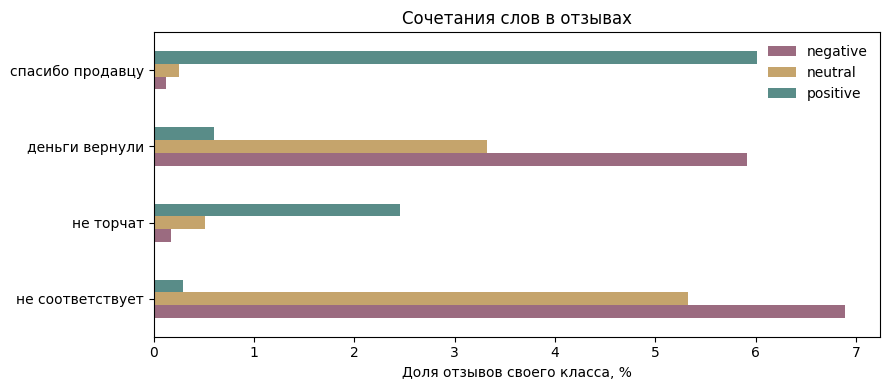

In [ ]:
pairs = [("не", "соответствует"), ("не", "торчат"), ("деньги", "вернули"), ("спасибо", "продавцу")]
presence = pd.DataFrame({" ".join(pair): bigram_sets.map(lambda found: pair in found) for pair in pairs})
rates = presence.groupby(df["label"]).mean().mul(100).reindex(LABELS)
ax = rates.T.plot.barh(figsize=(9, 4), color=COLORS)
ax.set(xlabel="Доля отзывов своего класса, %", ylabel="", title="Сочетания слов в отзывах")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Вопрос:** почему «не торчат» чаще встречается в положительных отзывах, а «деньги вернули» - в отрицательных и нейтральных? Проверьте свои объяснения по исходным текстам.

In [ ]:
df.loc[df["text_raw"].str.contains("деньги вернули", case=False, regex=False),
       ["text_raw", "label"]].sample(5, random_state=SEED)

,text_raw,label
49744,"Не получила товар, деньги вернули",neutral
23624,"пришла с браком, продавец намекал что майка была повреждена мной. деньги вернули через спор.",negative
42141,товар не пришёл. деньги вернули.,neutral
6842,"Товар пришёл спустя четыре месяца после окончания всех споров, деньги вернули",negative
10484,ужасно! открыла спор -деньги вернули черезн несколько дней!,negative
